In [1]:
import sys

print("Python version:", sys.version)
print("Python executable:", sys.executable)

Python version: 3.11.14 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 18:30:03) [MSC v.1929 64 bit (AMD64)]
Python executable: c:\Users\DELL\Documents\fraud-detection-ml\.venv\Scripts\python.exe


In [2]:
import importlib.util

packages = [
    "numpy",
    "pandas",
    "matplotlib",
    "seaborn",
    "sklearn",
    "xgboost",
    "imblearn",
    "shap",
    "jupyter",
]

for package in packages:
    status = "Installed" if importlib.util.find_spec(package) else "Not installed"
    print(f"{package}: {status}")

numpy: Installed
pandas: Installed
matplotlib: Installed
seaborn: Installed
sklearn: Installed
xgboost: Installed
imblearn: Installed
shap: Installed
jupyter: Installed


In [3]:
%pip install numpy pandas matplotlib seaborn scikit-learn xgboost imbalanced-learn shap

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import numpy as np
import pandas as pd
import sklearn
import xgboost
import imblearn
import shap
import matplotlib
import seaborn as sns

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)
print("Imbalanced-learn:", imblearn.__version__)
print("SHAP:", shap.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)

NumPy: 2.4.6
Pandas: 3.1.0
Scikit-learn: 1.9.1
XGBoost: 3.2.0
Imbalanced-learn: 0.14.2
SHAP: 0.51.0
Matplotlib: 3.11.2
Seaborn: 0.13.2


In [5]:
%pip install ipywidgets

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
from pathlib import Path
import pandas as pd

# Define the dataset location
data_path = Path("../data/raw/creditcard.csv")

# Check whether the file exists
if data_path.exists():
    print("Dataset found!")

    # Load the CSV file
    df = pd.read_csv(data_path)

    print("Dataset loaded successfully.")
    print("Dataset shape:", df.shape)
else:
    print("Dataset not found.")
    print("Expected location:", data_path.resolve())

Dataset found!
Dataset loaded successfully.
Dataset shape: (284807, 31)


In [7]:
print("First 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nTotal missing values:")
print(df.isnull().sum().sum())

print("\nTarget distribution:")
print(df["Class"].value_counts())

print("\nTarget percentages:")
print((df["Class"].value_counts(normalize=True) * 100).round(4))

First 5 rows:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



Column names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Data types:
Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object

Total missing values:
0

Target distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Target percentages:
Class
0    99.8273
1     0.1727
Name: proportion, dtype: floa

In [8]:
# Check duplicate rows
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

# Inspect transaction amounts
print("\nTransaction amount summary:")
display(df["Amount"].describe())

# Check target labels
print("\nUnique Class values:")
print(sorted(df["Class"].unique()))

# Confirm the dataset dimensions
print("\nDataset shape:", df.shape)

Duplicate rows: 1081

Transaction amount summary:


count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64


Unique Class values:
[np.int64(0), np.int64(1)]

Dataset shape: (284807, 31)


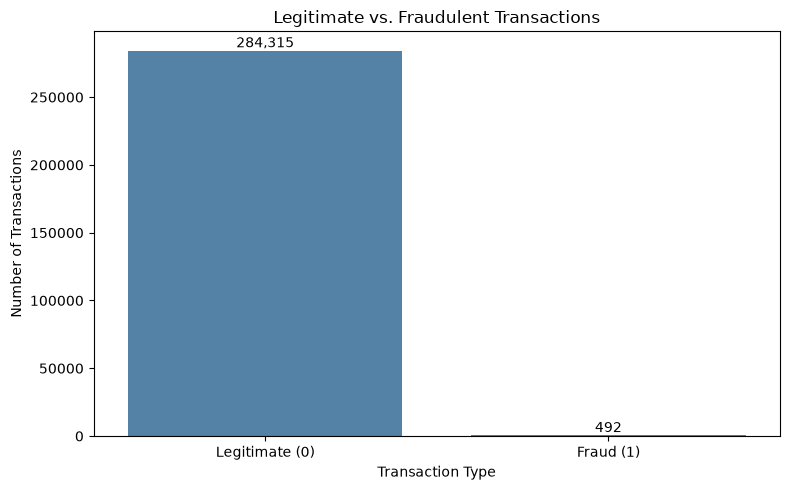

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count transactions in each class
class_counts = df["Class"].value_counts().sort_index()

# Create the chart
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    x=["Legitimate (0)", "Fraud (1)"],
    y=class_counts.values,
    color="steelblue"
)

plt.title("Legitimate vs. Fraudulent Transactions")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")

# Add count labels above the bars
for i, count in enumerate(class_counts.values):
    ax.text(i, count, f"{count:,}", ha="center", va="bottom")

plt.tight_layout()
plt.show()

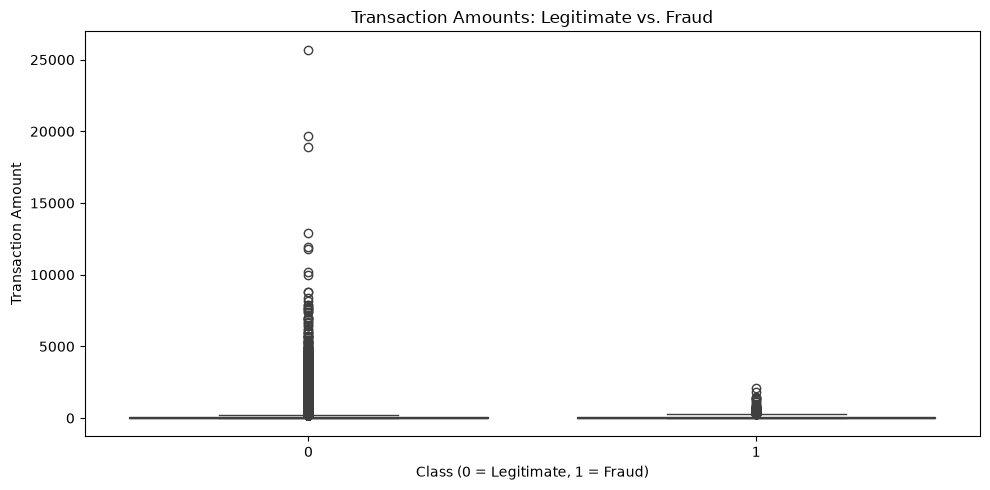

In [10]:
# Compare transaction amounts for legitimate and fraudulent transactions

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="Class",
    y="Amount"
)

plt.title("Transaction Amounts: Legitimate vs. Fraud")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Transaction Amount")
plt.tight_layout()
plt.show()

In [11]:
# Summarize transaction amounts separately for each class

amount_summary = df.groupby("Class")["Amount"].agg(
    ["count", "mean", "median", "min", "max", "std"]
)

amount_summary.index = ["Legitimate (0)", "Fraud (1)"]

display(amount_summary.round(2))

,count,mean,median,min,max,std
Legitimate (0),284315,88.29,22.00,0.0,25691.16,250.11
Fraud (1),492,122.21,9.25,0.0,2125.87,256.68


In [12]:
duplicate_rows = df[df.duplicated(keep=False)].sort_values(
    by=["Time", "Amount"]
)

print("Rows involved in duplicate groups:", len(duplicate_rows))
print("\nClass distribution among duplicate rows:")
display(duplicate_rows["Class"].value_counts())

print("\nSample duplicate rows:")
display(duplicate_rows.head(10))

Rows involved in duplicate groups: 1854

Class distribution among duplicate rows:


Class
0    1822
1      32
Name: count, dtype: int64


Sample duplicate rows:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
34,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
35,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
32,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
33,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
112,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
113,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
114,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
115,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
220,145.0,-2.420413,1.947885,0.553646,0.983069,-0.281518,2.408958,-1.401613,-0.188299,0.675878,...,1.213826,-1.238620,0.006927,-1.724222,0.239603,-0.313703,-0.188281,0.119831,6.00,0
221,145.0,-2.420413,1.947885,0.553646,0.983069,-0.281518,2.408958,-1.401613,-0.188299,0.675878,...,1.213826,-1.238620,0.006927,-1.724222,0.239603,-0.313703,-0.188281,0.119831,6.00,0


In [13]:
# Check for identical features with conflicting fraud labels

feature_columns = [col for col in df.columns if col != "Class"]

label_counts = df.groupby(feature_columns, dropna=False)["Class"].nunique()

conflicting_groups = label_counts[label_counts > 1]

print("Groups with conflicting labels:", len(conflicting_groups))

# Count repeated occurrences beyond the first, separately by class
print("\nRepeated rows beyond the first occurrence, by class:")
display(df[df.duplicated(keep="first")]["Class"].value_counts().sort_index())

Groups with conflicting labels: 0

Repeated rows beyond the first occurrence, by class:


Class
0    1062
1      19
Name: count, dtype: int64

In [14]:
# Separate input features and target label

X = df.drop(columns=["Class"])
y = df["Class"]

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nTarget distribution:")
display(y.value_counts().rename(index={0: "Legitimate", 1: "Fraud"}))

print("\nMissing values in features:", X.isnull().sum().sum())
print("Missing values in target:", y.isnull().sum())

Feature matrix shape: (284807, 30)
Target vector shape: (284807,)

Target distribution:


Class
Legitimate    284315
Fraud            492
Name: count, dtype: int64


Missing values in features: 0
Missing values in target: 0


In [15]:
from sklearn.model_selection import train_test_split

# Split the data while preserving class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nTraining class distribution (%):")
display((y_train.value_counts(normalize=True) * 100).round(4))

print("\nTesting class distribution (%):")
display((y_test.value_counts(normalize=True) * 100).round(4))

print("\nFraud cases in training set:", int(y_train.sum()))
print("Fraud cases in test set:", int(y_test.sum()))

Training features: (227845, 30)
Testing features: (56962, 30)
Training target: (227845,)
Testing target: (56962,)

Training class distribution (%):


Class
0    99.8271
1     0.1729
Name: proportion, dtype: float64


Testing class distribution (%):


Class
0    99.828
1     0.172
Name: proportion, dtype: float64


Fraud cases in training set: 394
Fraud cases in test set: 98


In [16]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)

# Scale Amount and Time using training data only
scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[["Amount", "Time"]] = scaler.fit_transform(
    X_train[["Amount", "Time"]]
)

X_test_scaled[["Amount", "Time"]] = scaler.transform(
    X_test[["Amount", "Time"]]
)

# Train a baseline logistic regression model
baseline_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

baseline_model.fit(X_train_scaled, y_train)

# Generate predictions and fraud probabilities
y_pred = baseline_model.predict(X_test_scaled)
y_proba = baseline_model.predict_proba(X_test_scaled)[:, 1]

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification report:")
print(classification_report(y_test, y_pred, digits=4, zero_division=0))

print("PR-AUC (Average Precision):", round(average_precision_score(y_test, y_proba), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba), 4))

Confusion matrix:
[[56851    13]
 [   35    63]]

Classification report:
              precision    recall  f1-score   support

           0     0.9994    0.9998    0.9996     56864
           1     0.8289    0.6429    0.7241        98

    accuracy                         0.9992     56962
   macro avg     0.9142    0.8213    0.8619     56962
weighted avg     0.9991    0.9992    0.9991     56962

PR-AUC (Average Precision): 0.7432
ROC-AUC: 0.9559


In [17]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)

# Split the existing training data into training and validation sets
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Fit the scaler only on the subtraining data
val_scaler = StandardScaler()

X_subtrain_scaled = X_subtrain.copy()
X_val_scaled = X_val.copy()

X_subtrain_scaled[["Amount", "Time"]] = val_scaler.fit_transform(
    X_subtrain[["Amount", "Time"]]
)

X_val_scaled[["Amount", "Time"]] = val_scaler.transform(
    X_val[["Amount", "Time"]]
)

# Train a class-weighted model
weighted_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

weighted_model.fit(X_subtrain_scaled, y_subtrain)

# Evaluate on the validation set
y_val_pred = weighted_model.predict(X_val_scaled)
y_val_proba = weighted_model.predict_proba(X_val_scaled)[:, 1]

print("Validation confusion matrix:")
print(confusion_matrix(y_val, y_val_pred))

print("\nValidation classification report:")
print(classification_report(
    y_val, y_val_pred, digits=4, zero_division=0
))

print(
    "Validation PR-AUC:",
    round(average_precision_score(y_val, y_val_proba), 4)
)
print(
    "Validation ROC-AUC:",
    round(roc_auc_score(y_val, y_val_proba), 4)
)

Validation confusion matrix:
[[44386  1104]
 [    9    70]]

Validation classification report:
              precision    recall  f1-score   support

           0     0.9998    0.9757    0.9876     45490
           1     0.0596    0.8861    0.1117        79

    accuracy                         0.9756     45569
   macro avg     0.5297    0.9309    0.5497     45569
weighted avg     0.9982    0.9756    0.9861     45569

Validation PR-AUC: 0.6788
Validation ROC-AUC: 0.9736


In [18]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix
)
import pandas as pd

# Train an unweighted baseline on the same subtraining data
regular_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

regular_model.fit(X_subtrain_scaled, y_subtrain)

# Get predictions and probabilities from both models
regular_pred = regular_model.predict(X_val_scaled)
regular_proba = regular_model.predict_proba(X_val_scaled)[:, 1]

weighted_pred = weighted_model.predict(X_val_scaled)
weighted_proba = weighted_model.predict_proba(X_val_scaled)[:, 1]

# Build a fair comparison using the same validation set
results = []

for model_name, predictions, probabilities in [
    ("Regular Logistic Regression", regular_pred, regular_proba),
    ("Class-Weighted Logistic Regression", weighted_pred, weighted_proba)
]:
    results.append({
        "Model": model_name,
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1-score": f1_score(y_val, predictions, zero_division=0),
        "PR-AUC": average_precision_score(y_val, probabilities),
        "ROC-AUC": roc_auc_score(y_val, probabilities),
        "False Positives": int(((y_val == 0) & (predictions == 1)).sum()),
        "Missed Fraud": int(((y_val == 1) & (predictions == 0)).sum())
    })

comparison_df = pd.DataFrame(results).set_index("Model")

display(comparison_df.round(4))

,Precision,Recall,F1-score,PR-AUC,ROC-AUC,False Positives,Missed Fraud
Model,,,,,,,
Regular Logistic Regression,0.8298,0.4937,0.6190,0.7079,0.9625,8,40
Class-Weighted Logistic Regression,0.0596,0.8861,0.1117,0.6788,0.9736,1104,9


In [19]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

# Use the regular model's validation probabilities
thresholds = [0.10, 0.20, 0.30, 0.40, 0.50]

threshold_results = []

for threshold in thresholds:
    # Convert probabilities into fraud predictions
    predictions = (regular_proba >= threshold).astype(int)

    # Count false positives and missed fraud
    false_positives = int(((y_val == 0) & (predictions == 1)).sum())
    missed_fraud = int(((y_val == 1) & (predictions == 0)).sum())

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "False Positives": false_positives,
        "Missed Fraud": missed_fraud
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(4))

,Threshold,Precision,Recall,F1-score,False Positives,Missed Fraud
0,0.1,0.7879,0.6582,0.7172,14,27
1,0.2,0.8095,0.6456,0.7183,12,28
2,0.3,0.8167,0.6203,0.7050,11,30
3,0.4,0.8077,0.5316,0.6412,10,37
4,0.5,0.8298,0.4937,0.6190,8,40


In [20]:
from xgboost import XGBClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)

# Calculate the training class imbalance ratio
negative_count = int((y_subtrain == 0).sum())
positive_count = int((y_subtrain == 1).sum())

print("Legitimate transactions:", negative_count)
print("Fraudulent transactions:", positive_count)
print("Negative/positive ratio:", round(negative_count / positive_count, 2))

# Train an initial XGBoost model
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="aucpr",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

# Tree models do not require feature scaling
xgb_model.fit(X_subtrain, y_subtrain)

# Evaluate on the same validation set
xgb_pred = xgb_model.predict(X_val)
xgb_proba = xgb_model.predict_proba(X_val)[:, 1]

print("\nXGBoost confusion matrix:")
print(confusion_matrix(y_val, xgb_pred))

print("\nXGBoost classification report:")
print(classification_report(
    y_val, xgb_pred, digits=4, zero_division=0
))

print(
    "XGBoost PR-AUC:",
    round(average_precision_score(y_val, xgb_proba), 4)
)
print(
    "XGBoost ROC-AUC:",
    round(roc_auc_score(y_val, xgb_proba), 4)
)

Legitimate transactions: 181961
Fraudulent transactions: 315
Negative/positive ratio: 577.65



XGBoost confusion matrix:
[[45487     3]
 [   20    59]]

XGBoost classification report:
              precision    recall  f1-score   support

           0     0.9996    0.9999    0.9997     45490
           1     0.9516    0.7468    0.8369        79

    accuracy                         0.9995     45569
   macro avg     0.9756    0.8734    0.9183     45569
weighted avg     0.9995    0.9995    0.9995     45569

XGBoost PR-AUC: 0.8513
XGBoost ROC-AUC: 0.9804


In [21]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Test different probability thresholds for XGBoost
thresholds = [0.10, 0.20, 0.30, 0.40, 0.50]

xgb_threshold_results = []

for threshold in thresholds:

    # Convert probabilities into fraud predictions
    predictions = (xgb_proba >= threshold).astype(int)

    # Calculate false positives and missed fraud
    false_positives = int(
        ((y_val == 0) & (predictions == 1)).sum()
    )

    missed_fraud = int(
        ((y_val == 1) & (predictions == 0)).sum()
    )

    xgb_threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "False Positives": false_positives,
        "Missed Fraud": missed_fraud
    })

xgb_threshold_df = pd.DataFrame(xgb_threshold_results)

display(xgb_threshold_df.round(4))

,Threshold,Precision,Recall,F1-score,False Positives,Missed Fraud
0,0.1,0.8333,0.8228,0.8280,13,14
1,0.2,0.8784,0.8228,0.8497,9,14
2,0.3,0.9286,0.8228,0.8725,5,14
3,0.4,0.9403,0.7975,0.8630,4,16
4,0.5,0.9516,0.7468,0.8369,3,20


In [22]:
# Check whether identical feature combinations appear across splits

feature_columns = [col for col in df.columns if col != "Class"]

# Assign the same group ID to identical feature combinations
group_ids = df.groupby(
    feature_columns,
    sort=False,
    dropna=False
).ngroup()

# Compare groups in subtraining and validation sets
subtrain_groups = set(group_ids.loc[X_subtrain.index])
validation_groups = set(group_ids.loc[X_val.index])

# Compare groups in the original training and test sets
train_groups = set(group_ids.loc[X_train.index])
test_groups = set(group_ids.loc[X_test.index])

subtrain_val_overlap = subtrain_groups.intersection(validation_groups)
train_test_overlap = train_groups.intersection(test_groups)

print(
    "Identical feature groups shared between subtraining and validation:",
    len(subtrain_val_overlap)
)

print(
    "Identical feature groups shared between training and test:",
    len(train_test_overlap)
)

Identical feature groups shared between subtraining and validation: 214
Identical feature groups shared between training and test: 293


In [23]:
from sklearn.model_selection import StratifiedGroupKFold

# Identify identical transactions using all features except the target
feature_columns = [col for col in df.columns if col != "Class"]

groups = df.groupby(
    feature_columns,
    sort=False,
    dropna=False
).ngroup()

# Step A: Create the training and untouched test sets
outer_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    outer_cv.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

groups_train = groups.iloc[train_idx]

# Step B: Split the training set into subtraining and validation
inner_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)

sub_idx, val_idx = next(
    inner_cv.split(X_train, y_train, groups=groups_train)
)

X_subtrain = X_train.iloc[sub_idx].copy()
X_val = X_train.iloc[val_idx].copy()

y_subtrain = y_train.iloc[sub_idx].copy()
y_val = y_train.iloc[val_idx].copy()

# Step C: Verify split sizes and fraud counts
print("SUBTRAINING SET")
print("Shape:", X_subtrain.shape)
print("Fraud cases:", y_subtrain.sum())

print("\nVALIDATION SET")
print("Shape:", X_val.shape)
print("Fraud cases:", y_val.sum())

print("\nTEST SET")
print("Shape:", X_test.shape)
print("Fraud cases:", y_test.sum())

# Step D: Verify that identical feature groups do not cross splits
subtrain_groups = set(groups.iloc[X_subtrain.index])
validation_groups = set(groups.iloc[X_val.index])
test_groups = set(groups.iloc[X_test.index])

print("\nGROUP OVERLAP CHECK")
print("Subtraining vs validation:", len(subtrain_groups & validation_groups))
print("Subtraining vs test:", len(subtrain_groups & test_groups))
print("Validation vs test:", len(validation_groups & test_groups))

SUBTRAINING SET
Shape: (182276, 30)
Fraud cases: 314

VALIDATION SET
Shape: (45569, 30)
Fraud cases: 79

TEST SET
Shape: (56962, 30)
Fraud cases: 99

GROUP OVERLAP CHECK
Subtraining vs validation: 0
Subtraining vs test: 0
Validation vs test: 0


In [24]:
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Make copies so the original datasets remain unchanged
X_subtrain_scaled = X_subtrain.copy()
X_val_scaled = X_val.copy()

# Fit only on subtraining data and transform it
X_subtrain_scaled[["Amount", "Time"]] = scaler.fit_transform(
    X_subtrain[["Amount", "Time"]]
)

# Transform validation data using the same scaler
X_val_scaled[["Amount", "Time"]] = scaler.transform(
    X_val[["Amount", "Time"]]
)

# Check the results
print("Subtraining shape:", X_subtrain_scaled.shape)
print("Validation shape:", X_val_scaled.shape)

print("\nScaled feature statistics:")
print(X_subtrain_scaled[["Amount", "Time"]].agg(["mean", "std"]).round(3))

print("\nMissing values after scaling:")
print(X_subtrain_scaled[["Amount", "Time"]].isnull().sum())

Subtraining shape: (182276, 30)
Validation shape: (45569, 30)

Scaled feature statistics:
      Amount  Time
mean    -0.0   0.0
std      1.0   1.0

Missing values after scaling:
Amount    0
Time      0
dtype: int64


In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    average_precision_score,
    roc_auc_score
)

# Initialize the model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train using subtraining data
logistic_model.fit(X_subtrain_scaled, y_subtrain)

# Predict fraud labels and probabilities on validation data
logistic_pred = logistic_model.predict(X_val_scaled)
logistic_proba = logistic_model.predict_proba(X_val_scaled)[:, 1]

# Evaluate the model
print("Confusion Matrix:")
print(confusion_matrix(y_val, logistic_pred))

print("\nClassification Report:")
print(classification_report(y_val, logistic_pred, digits=4))

print("PR-AUC (Average Precision):",
      round(average_precision_score(y_val, logistic_proba), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_val, logistic_proba), 4))

Confusion Matrix:
[[45483     7]
 [   30    49]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9993    0.9998    0.9996     45490
           1     0.8750    0.6203    0.7259        79

    accuracy                         0.9992     45569
   macro avg     0.9372    0.8100    0.8628     45569
weighted avg     0.9991    0.9992    0.9991     45569

PR-AUC (Average Precision): 0.7887
ROC-AUC: 0.9936


In [26]:
from xgboost import XGBClassifier
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    average_precision_score,
    roc_auc_score
)

# Initialize XGBoost
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="aucpr",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

# Train using original, unscaled features
xgb_model.fit(X_subtrain, y_subtrain)

# Predict labels and fraud probabilities
xgb_pred = xgb_model.predict(X_val)
xgb_proba = xgb_model.predict_proba(X_val)[:, 1]

# Evaluate
print("Confusion Matrix:")
print(confusion_matrix(y_val, xgb_pred))

print("\nClassification Report:")
print(classification_report(y_val, xgb_pred, digits=4))

print("PR-AUC (Average Precision):",
      round(average_precision_score(y_val, xgb_proba), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_val, xgb_proba), 4))

Confusion Matrix:
[[45485     5]
 [   12    67]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9997    0.9999    0.9998     45490
           1     0.9306    0.8481    0.8874        79

    accuracy                         0.9996     45569
   macro avg     0.9651    0.9240    0.9436     45569
weighted avg     0.9996    0.9996    0.9996     45569

PR-AUC (Average Precision): 0.8952
ROC-AUC: 0.9937


In [27]:
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

results = []

for threshold in thresholds:

    # Convert probabilities into predictions
    y_pred_threshold = (xgb_proba >= threshold).astype(int)

    # Calculate confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_val, y_pred_threshold
    ).ravel()

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, y_pred_threshold, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_pred_threshold, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, y_pred_threshold, zero_division=0
        ),
        "False Positives": fp,
        "Missed Fraud": fn,
        "Fraud Detected": tp
    })

threshold_results = pd.DataFrame(results)

print(threshold_results.round(4).to_string(index=False))


 Threshold  Precision  Recall  F1 Score  False Positives  Missed Fraud  Fraud Detected
      0.10     0.8861  0.8861    0.8861                9             9              70
      0.15     0.9211  0.8861    0.9032                6             9              70
      0.20     0.9333  0.8861    0.9091                5             9              70
      0.25     0.9333  0.8861    0.9091                5             9              70
      0.30     0.9333  0.8861    0.9091                5             9              70
      0.35     0.9333  0.8861    0.9091                5             9              70
      0.40     0.9324  0.8734    0.9020                5            10              69
      0.45     0.9315  0.8608    0.8947                5            11              68
      0.50     0.9306  0.8481    0.8874                5            12              67


In [28]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)

# Predict fraud probabilities on the untouched test set
test_proba = xgb_model.predict_proba(X_test)[:, 1]

# Apply the threshold selected using validation data
selected_threshold = 0.20
test_pred = (test_proba >= selected_threshold).astype(int)

# Confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_test, test_pred
).ravel()

print("FINAL TEST RESULTS")
print("=" * 40)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_pred))

print("\nClassification Report:")
print(classification_report(y_test, test_pred, digits=4))

print("Precision:", round(precision_score(y_test, test_pred), 4))
print("Recall:", round(recall_score(y_test, test_pred), 4))
print("F1 Score:", round(f1_score(y_test, test_pred), 4))

print("PR-AUC:", round(average_precision_score(y_test, test_proba), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, test_proba), 4))

print("\nBusiness Impact:")
print("Fraud detected:", tp)
print("Fraud missed:", fn)
print("Legitimate transactions flagged:", fp)
print("Legitimate transactions correctly identified:", tn)

FINAL TEST RESULTS

Confusion Matrix:
[[56856     7]
 [   17    82]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9997    0.9999    0.9998     56863
           1     0.9213    0.8283    0.8723        99

    accuracy                         0.9996     56962
   macro avg     0.9605    0.9141    0.9361     56962
weighted avg     0.9996    0.9996    0.9996     56962

Precision: 0.9213
Recall: 0.8283
F1 Score: 0.8723
PR-AUC: 0.8611
ROC-AUC: 0.9887

Business Impact:
Fraud detected: 82
Fraud missed: 17
Legitimate transactions flagged: 7
Legitimate transactions correctly identified: 56856


In [29]:
import shap

# Select 1,000 validation transactions for explanation
X_shap = X_val.sample(
    n=min(1000, len(X_val)),
    random_state=42
)

# Create a TreeExplainer for XGBoost
explainer = shap.TreeExplainer(xgb_model)

# Calculate SHAP values
shap_values = explainer(X_shap)

print("SHAP explanation completed.")
print("Explanation shape:", shap_values.values.shape)
print("Number of transactions explained:", len(X_shap))
print("Number of features:", X_shap.shape[1])

SHAP explanation completed.
Explanation shape: (1000, 30)
Number of transactions explained: 1000
Number of features: 30


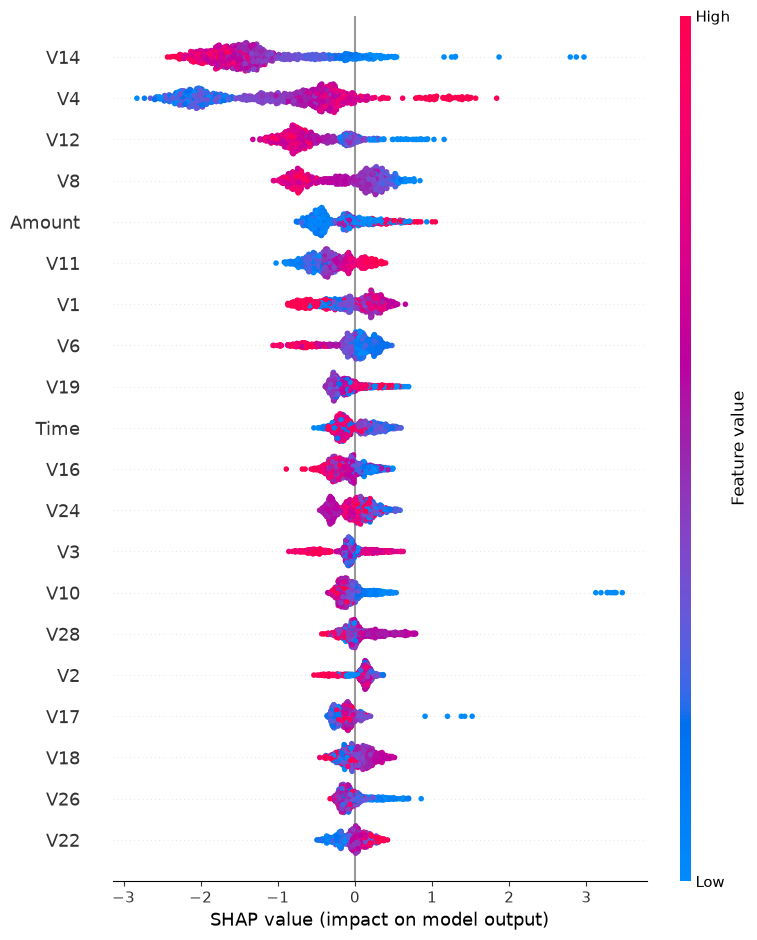

In [30]:
import matplotlib.pyplot as plt

# Global feature importance and direction of impact
shap.summary_plot(
    shap_values,
    X_shap,
    max_display=20
)

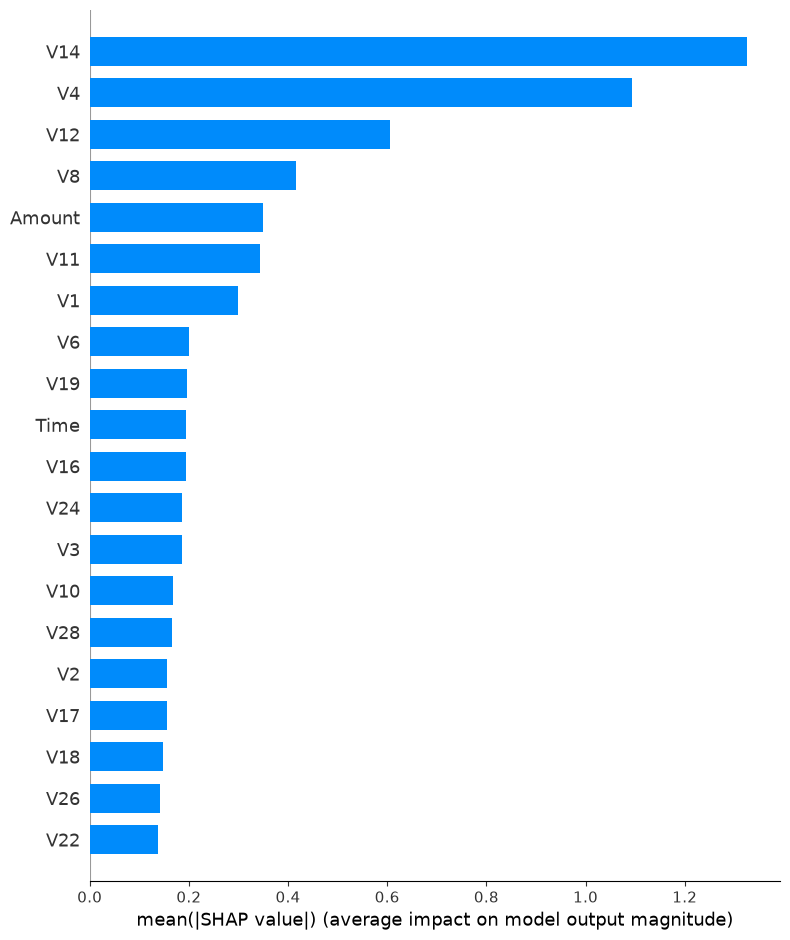

In [31]:
shap.summary_plot(
    shap_values,
    X_shap,
    plot_type="bar",
    max_display=20
)

Correctly detected fraud transactions: 70

Selected transaction index: 541
Actual class: 1
Predicted fraud probability: 0.9763
Prediction threshold: 0.2


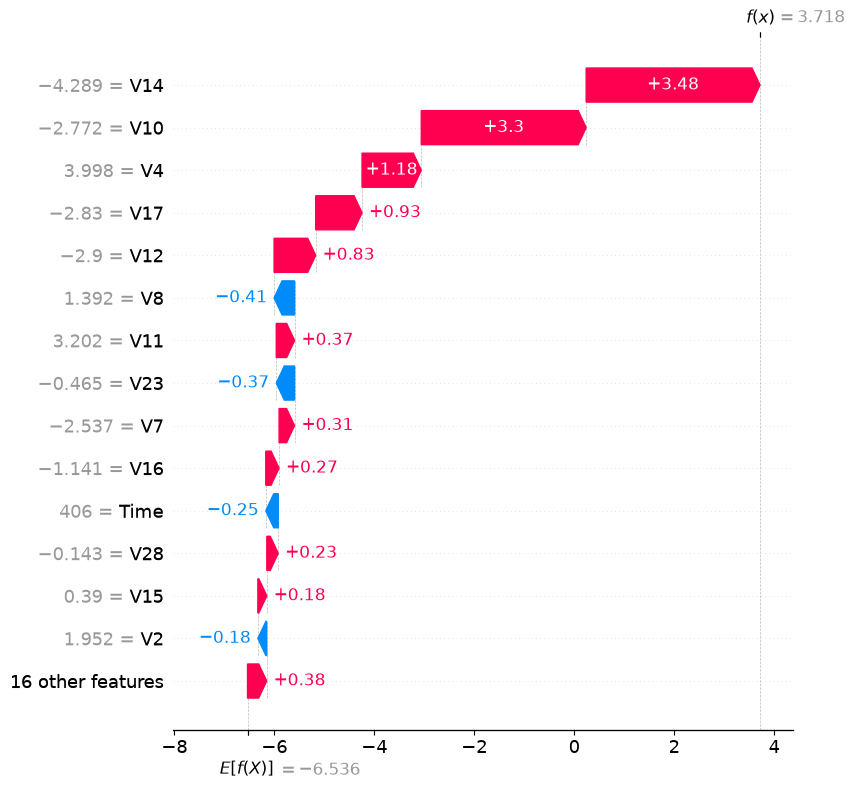

In [32]:
# Find fraud transactions correctly predicted by XGBoost
validation_predictions = (
    xgb_model.predict_proba(X_val)[:, 1] >= selected_threshold
)

correct_fraud_indices = X_val.index[
    (y_val == 1) & validation_predictions
]

print("Correctly detected fraud transactions:",
      len(correct_fraud_indices))

# Select one transaction
transaction_index = correct_fraud_indices[0]

# Generate SHAP explanation for this transaction
single_transaction = X_val.loc[[transaction_index]]
single_shap = explainer(single_transaction)

print("\nSelected transaction index:", transaction_index)
print("Actual class:", y_val.loc[transaction_index])
print("Predicted fraud probability:",
      round(xgb_model.predict_proba(single_transaction)[0, 1], 4))
print("Prediction threshold:", selected_threshold)

# Visualize individual explanation
shap.plots.waterfall(
    single_shap[0],
    max_display=15
)

In [33]:
from pathlib import Path
import json

# Create the models directory
models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

# Save the trained XGBoost model
model_path = models_dir / "fraud_xgboost.json"
xgb_model.save_model(str(model_path))

# Save model configuration and evaluation details
model_metadata = {
    "model_name": "XGBoost Fraud Detection",
    "model_type": "XGBClassifier",
    "threshold": selected_threshold,
    "number_of_features": len(X_train.columns),
    "features": X_train.columns.tolist(),
    "class_mapping": {
        "0": "Legitimate",
        "1": "Fraud"
    },
    "test_metrics": {
        "precision": 0.9213,
        "recall": 0.8283,
        "f1_score": 0.8723,
        "pr_auc": 0.8611,
        "roc_auc": 0.9887
    }
}

metadata_path = models_dir / "model_metadata.json"

with open(metadata_path, "w") as file:
    json.dump(model_metadata, file, indent=4)

# Verify saved files
print("Model saved:", model_path.resolve())
print("Metadata saved:", metadata_path.resolve())

print("\nSaved model exists:", model_path.exists())
print("Saved metadata exists:", metadata_path.exists())
print("Model size:", round(model_path.stat().st_size / 1024, 2), "KB")

Model saved: C:\Users\DELL\Documents\fraud-detection-ml\models\fraud_xgboost.json
Metadata saved: C:\Users\DELL\Documents\fraud-detection-ml\models\model_metadata.json

Saved model exists: True
Saved metadata exists: True
Model size: 502.17 KB


In [34]:
import numpy as np
from xgboost import XGBClassifier
import json

# Load the saved model into a new model object
loaded_model = XGBClassifier()
loaded_model.load_model(str(model_path))

# Generate predictions using both models
original_proba = xgb_model.predict_proba(X_test)[:, 1]
loaded_proba = loaded_model.predict_proba(X_test)[:, 1]

# Compare probability predictions
print("Original model first 5 probabilities:")
print(original_proba[:5])

print("\nLoaded model first 5 probabilities:")
print(loaded_proba[:5])

# Check whether predictions match
print("\nMaximum probability difference:",
      np.max(np.abs(original_proba - loaded_proba)))

print("Predictions match:",
      np.allclose(original_proba, loaded_proba, atol=1e-7))

# Verify metadata
with open(metadata_path, "r") as file:
    loaded_metadata = json.load(file)

print("\nSaved threshold:", loaded_metadata["threshold"])
print("Saved feature count:", loaded_metadata["number_of_features"])

Original model first 5 probabilities:
[2.2129932e-05 3.8341932e-05 3.9960323e-05 9.2188930e-05 2.3940149e-05]

Loaded model first 5 probabilities:
[2.2129932e-05 3.8341932e-05 3.9960323e-05 9.2188930e-05 2.3940149e-05]

Maximum probability difference: 0.0
Predictions match: True

Saved threshold: 0.2
Saved feature count: 30


In [35]:
import json

# Find legitimate transactions correctly classified by XGBoost
legitimate_indices = X_val.index[
    (y_val == 0) & (xgb_proba < selected_threshold)
]

# Select one legitimate transaction
transaction_index = legitimate_indices[0]

# Extract original, unscaled feature values
legitimate_transaction = X_val.loc[transaction_index]

# Convert NumPy values into standard Python floats
request_data = {
    feature: float(legitimate_transaction[feature])
    for feature in X_val.columns
}

print("Transaction index:", transaction_index)
print("Actual class:", y_val.loc[transaction_index])
print("Model fraud probability:",
      round(float(xgb_model.predict_proba(
          X_val.loc[[transaction_index]]
      )[0, 1]), 6))

print("\nCopy this JSON into Swagger:")
print(json.dumps(request_data, indent=4))

Transaction index: 1
Actual class: 0
Model fraud probability: 7.3e-05

Copy this JSON into Swagger:
{
    "Time": 0.0,
    "V1": 1.19185711131486,
    "V2": 0.26615071205963,
    "V3": 0.16648011335321,
    "V4": 0.448154078460911,
    "V5": 0.0600176492822243,
    "V6": -0.0823608088155687,
    "V7": -0.0788029833323113,
    "V8": 0.0851016549148104,
    "V9": -0.255425128109186,
    "V10": -0.166974414004614,
    "V11": 1.61272666105479,
    "V12": 1.06523531137287,
    "V13": 0.48909501589608,
    "V14": -0.143772296441519,
    "V15": 0.635558093258208,
    "V16": 0.463917041022171,
    "V17": -0.114804663102346,
    "V18": -0.183361270123994,
    "V19": -0.145783041325259,
    "V20": -0.0690831352230203,
    "V21": -0.225775248033138,
    "V22": -0.638671952771851,
    "V23": 0.101288021253234,
    "V24": -0.339846475529127,
    "V25": 0.167170404418143,
    "V26": 0.125894532368176,
    "V27": -0.00898309914322813,
    "V28": 0.0147241691924927,
    "Amount": 2.69
}


In [36]:
import json

legitimate_indices = X_val.index[
    (y_val == 0) & (xgb_proba < selected_threshold)
]

transaction_index = legitimate_indices[0]

legitimate_transaction = X_val.loc[transaction_index]

request_data = {
    feature: float(legitimate_transaction[feature])
    for feature in X_val.columns
}

print("Transaction index:", transaction_index)
print("Actual class:", y_val.loc[transaction_index])
print(
    "Fraud probability:",
    round(float(xgb_model.predict_proba(
        X_val.loc[[transaction_index]]
    )[0, 1]), 6)
)

print(json.dumps(request_data, indent=4))

Transaction index: 1
Actual class: 0
Fraud probability: 7.3e-05
{
    "Time": 0.0,
    "V1": 1.19185711131486,
    "V2": 0.26615071205963,
    "V3": 0.16648011335321,
    "V4": 0.448154078460911,
    "V5": 0.0600176492822243,
    "V6": -0.0823608088155687,
    "V7": -0.0788029833323113,
    "V8": 0.0851016549148104,
    "V9": -0.255425128109186,
    "V10": -0.166974414004614,
    "V11": 1.61272666105479,
    "V12": 1.06523531137287,
    "V13": 0.48909501589608,
    "V14": -0.143772296441519,
    "V15": 0.635558093258208,
    "V16": 0.463917041022171,
    "V17": -0.114804663102346,
    "V18": -0.183361270123994,
    "V19": -0.145783041325259,
    "V20": -0.0690831352230203,
    "V21": -0.225775248033138,
    "V22": -0.638671952771851,
    "V23": 0.101288021253234,
    "V24": -0.339846475529127,
    "V25": 0.167170404418143,
    "V26": 0.125894532368176,
    "V27": -0.00898309914322813,
    "V28": 0.0147241691924927,
    "Amount": 2.69
}
